# 04b — Regression run: summary for the report

The numbers and figures of stage 3.1 (baseline) and stage 3.2 (regression run),
condensed for the thesis. `03_baseline` and `04_regress` hold the working, the
failures one by one and the reasoning; this notebook only summarises them, and
reads everything from the stored runs (no judge is called).

- **Baseline:** run `1a872c09`, adopted by the author (D96).
- **Regression run:** run `e097f78e`, the same configuration, compared
  pair-wise against the baseline in both orderings (D23, D97).
- **Pass rule in force:** D88: seeds pass at 8/8, follow-ups at ≥ 75 %; a
  structural `detected` fails an execution; a contradictory pair of orderings
  is a position draw and passes. D23's strict reading is shown beside it.

Descriptive only (D104): counts, rates and differences, with no interval and
no test. Every rate is shown with the counts behind it. Figures are written to
`figures/regression/` as PDF and PNG.

In [1]:
import sys, pathlib, statistics
sys.path.insert(0, str(pathlib.Path.cwd().resolve().parents[1]))

import matplotlib.pyplot as plt
import pandas as pd

from src import analysis, comparison as cmp, db, figures, survey
from src.cases import load_cases
from src.scoring import scores_for

pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 200)

# --- parameters -------------------------------------------------------------
BASELINE_RUN_ID = "1a872c09-7070-4789-a806-904969f9185d"
CANDIDATE_RUN_ID = "e097f78e-3326-4aea-acaa-0b904d3b0a1c"
# ---------------------------------------------------------------------------

figures.setup()
save = figures.Saver("regression")
RUN_COLOR = {"baseline": figures.ROUND_COLOR["simulation"], "regression": figures.ROUND_COLOR["participant"]}
pct = "{:.1%}".format

cases = {c.case_id: c for c in load_cases()}
baseline = cmp.load_baseline(cmp.ADOPTED_BASELINE)
runs = {"baseline": survey.run_frame(BASELINE_RUN_ID), "regression": survey.run_frame(CANDIDATE_RUN_ID)}
comparisons = cmp.compare_run(CANDIDATE_RUN_ID, baseline, log=lambda m: None)  # read from study_comparisons
rates = cmp.pass_rates(comparisons)
strict = cmp.pass_rates(comparisons, "strict")
print(f"{len(rates)} cases; baseline {BASELINE_RUN_ID[:8]}: {len(runs['baseline'])} executions; "
      f"regression {CANDIDATE_RUN_ID[:8]}: {len(runs['regression'])} executions, {len(comparisons)} compared")

31 cases; baseline 1a872c09: 176 executions; regression e097f78e: 176 executions, 176 compared


## 1. The two runs at a glance

In [2]:
def run_summary(f):
    n = len(f)
    failed = int(f["error"].notna().sum())
    clean = int((f["structural"] == "none").sum())
    s = f["score"].dropna()
    return {
        "cases": f["case"].nunique(), "executions": n, "execution failures": failed,
        "structurally clean": f"{clean}/{n} = {pct(clean / n)}" if n else "–",
        "judge score mean ± sd": f"{s.mean():.2f} ± {s.std():.2f} (n = {len(s)})",
        "judge score median [IQR]": f"{s.median():.0f} [{s.quantile(.25):.0f}–{s.quantile(.75):.0f}]",
        "latency median / p90, s": f"{f['latency_ms'].median() / 1000:.1f} / {f['latency_ms'].quantile(.9) / 1000:.1f}",
        "tokens per execution, median": f"{f['tokens'].median():,.0f}",
        "cost total / per execution, USD": f"{f['cost_usd'].sum():.2f} / {f['cost_usd'].mean():.4f}",
    }

overview = pd.DataFrame({name: run_summary(f) for name, f in runs.items()})
d = runs["regression"]["score"].mean() - runs["baseline"]["score"].mean()
print(f"mean judge score, regression − baseline: {d:+.2f}")
overview

mean judge score, regression − baseline: +0.23


,baseline,regression
cases,31,31
executions,176,176
execution failures,0,0
structurally clean,165/176 = 93.8%,168/176 = 95.5%
judge score mean ± sd,9.26 ± 1.34 (n = 176),9.48 ± 0.87 (n = 176)
judge score median [IQR],10 [9–10],10 [9–10]
"latency median / p90, s",20.5 / 49.2,19.7 / 49.1
"tokens per execution, median","12,465","12,459"
"cost total / per execution, USD",4.52 / 0.0257,4.41 / 0.0251


## 2. Verdicts

Case verdicts under the rule in force (D88) and D23's strict reading, split by
provenance and by function. The execution pass rate pools every execution, as
a single number for the report.

In [3]:
rates["function"] = [cases[c].function if c in cases else "?" for c in rates.index]
verdicts = pd.DataFrame({
    "D88 (in force)": rates["verdict"].value_counts(),
    "D23 strict": strict["verdict"].value_counts(),
}).fillna(0).astype(int)
by = pd.crosstab([rates["provenance"]], rates["verdict"], margins=True, margins_name="all")
by_fn = pd.crosstab(rates["function"], rates["verdict"], margins=True, margins_name="all")

decided = [c for c in comparisons if c.passed is not None]
k = sum(1 for c in decided if c.passed)
ks = sum(1 for c in decided if cmp.passed_under(c, "strict"))
print(f"executions passing: D88 {k}/{len(decided)} = {pct(k / len(decided))}; "
      f"D23 strict {ks}/{len(decided)} = {pct(ks / len(decided))}")
display(verdicts); display(by); by_fn

executions passing: D88 136/176 = 77.3%; D23 strict 109/176 = 61.9%


,D88 (in force),D23 strict
verdict,,
fail,9,17
pass,22,14


verdict,fail,pass,all
provenance,,,
metamorphic,2,16,18
seeded,7,6,13
all,9,22,31


verdict,fail,pass,all
function,,,
advisory,0,6,6
factual_qa,3,6,9
scheduling,3,6,9
venue_lookup,3,4,7
all,9,22,31


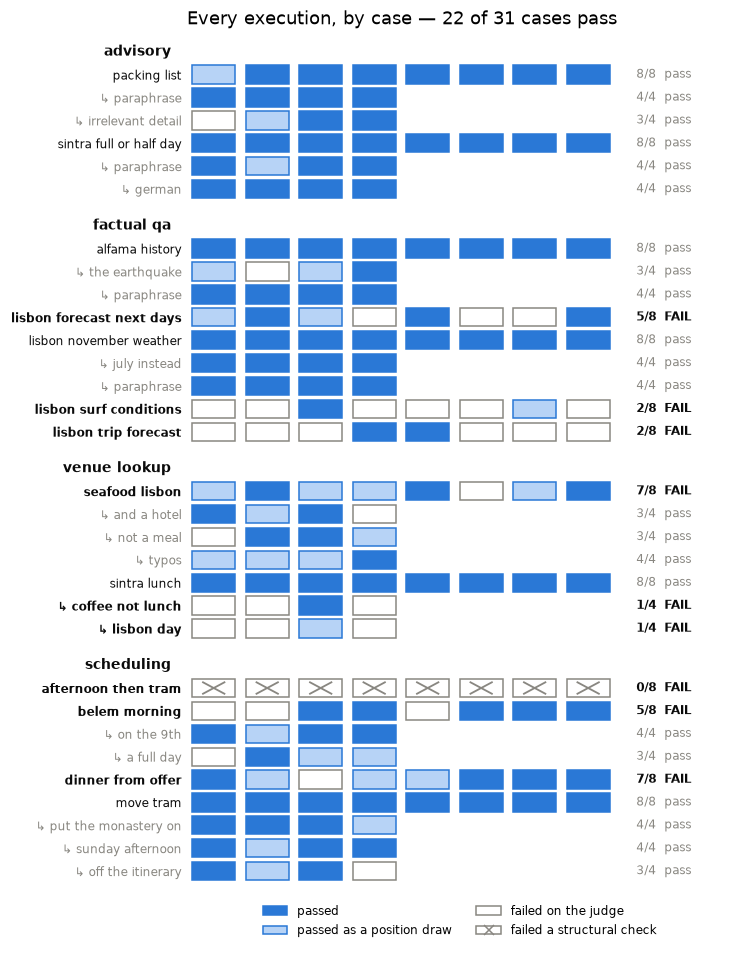

In [4]:
# Figure R1 — every execution of every case: filled = passed, light = passed as a position draw
# (D23 strict would fail it), empty = failed on the judge, crossed = failed a structural check.
# Seeds need 8/8, follow-ups 3 of 4.

def short(case_id):
    """'venue_lookup_seafood_lisbon__dir1_and_a_hotel' -> ('seafood lisbon', 'and a hotel')."""
    base, _, rel = case_id.partition("__")
    fn = cases[case_id].function if case_id in cases else ""
    base = base[len(fn) + 1:] if base.startswith(fn + "_") else base
    return base.replace("_", " "), rel.split("_", 1)[1].replace("_", " ") if rel else None

def cell(c):
    if c.structural == "detected":
        return "structural"
    if c.passed is False:
        return "fail"
    return "draw" if c.position_draw else "pass"

FUNCTIONS = ["advisory", "factual_qa", "venue_lookup", "scheduling"]
grid_rows = []
for fn in FUNCTIONS:
    seeds = sorted(c for c in rates.index if rates.loc[c, "function"] == fn and "__" not in c)
    for seed in seeds:
        for case in [seed] + sorted(c for c in rates.index if c.startswith(seed + "__")):
            mine = sorted((c for c in comparisons if c.case_id == case), key=lambda c: c.repetition)
            name, rel = short(case)
            grid_rows.append({"case": case, "label": rel or name, "indent": bool(rel), "group": fn.replace("_", " "),
                              "cells": [cell(c) for c in mine], "verdict": rates.loc[case, "verdict"]})

fig, ax = plt.subplots(figsize=(6.4, 0.24 * (len(grid_rows) + 2 * len(FUNCTIONS)) + 0.8))
figures.execution_grid(ax, grid_rows, f"Every execution, by case — {int((rates['verdict'] == 'pass').sum())} "
                                      f"of {len(rates)} cases pass")
figures.grid_legend(ax, {"pass": "passed", "draw": "passed as a position draw",
                         "fail": "failed on the judge", "structural": "failed a structural check"},
                    loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=2, fontsize=8)
save(fig, "R1_pass_rate_per_case"); plt.show()

## 3. Why cases fail

Every failing execution is either structural (a check of the case detected a
problem) or the judge's: the execution passes every structural check, and in
both orderings the judge finds its reply **not at least as good as the
baseline**. The baseline entry is each case's best-scoring clean execution
(D86), so this is a comparison against a strong reference. The configuration
did not change between the two runs (`04_regress` proves it).

In [5]:
fails = rates[rates["verdict"] == "fail"][["provenance", "function", "executions", "passed",
                                            "structural fails", "judge prefers baseline", "position draws",
                                            "pass rate", "pass rate (strict)"]]
struct_cases = int((fails["structural fails"] > 0).sum())
judge_only = int(((fails["structural fails"] == 0) & (fails["judge prefers baseline"] > 0)).sum())
print(f"failing cases: {len(fails)} — structural {struct_cases}, judge only {judge_only}")
print(f"cases failing on the judge alone (structural checks passed, reply judged not at least as good as the "
      f"baseline): {judge_only}/{len(rates)} = {pct(judge_only / len(rates))}")
fails.assign(**{"pass rate": fails["pass rate"].map(pct), "pass rate (strict)": fails["pass rate (strict)"].map(pct)})

failing cases: 9 — structural 1, judge only 8
cases failing on the judge alone (structural checks passed, reply judged not at least as good as the baseline): 8/31 = 25.8%


,provenance,function,executions,passed,structural fails,judge prefers baseline,position draws,pass rate,pass rate (strict)
case,,,,,,,,,
factual_qa_lisbon_forecast_next_days,seeded,factual_qa,8,5,0,3,2,62.5%,37.5%
factual_qa_lisbon_surf_conditions,seeded,factual_qa,8,2,0,6,1,25.0%,12.5%
factual_qa_lisbon_trip_forecast,seeded,factual_qa,8,2,0,6,0,25.0%,25.0%
scheduling_afternoon_then_tram,seeded,scheduling,8,0,8,0,0,0.0%,0.0%
scheduling_belem_morning,seeded,scheduling,8,5,0,3,0,62.5%,62.5%
scheduling_dinner_from_offer,seeded,scheduling,8,7,0,1,3,87.5%,50.0%
venue_lookup_seafood_lisbon,seeded,venue_lookup,8,7,0,1,4,87.5%,37.5%
venue_lookup_sintra_lunch__dir1_coffee_not_lunch,metamorphic,venue_lookup,4,1,0,3,0,25.0%,25.0%
venue_lookup_sintra_lunch__dir2_lisbon_day,metamorphic,venue_lookup,4,1,0,3,1,25.0%,0.0%


## 4. The pair-wise judge

How the two orderings answered, over every structurally clean pair. A
consistent pattern is a ranking; an inconsistent one (a lean in one ordering,
or the same slot picked both times) means the judge could not rank the two
replies the same way twice. An inconsistent pair that D23's strict reading
would fail is a **position draw** (D88): it passes. The inconsistency rate is
the judge's own noise.

In [6]:
judged = [c for c in comparisons if c.structural == "none" and len(c.orderings) == 2 and not c.error]
patterns = pd.Series([cmp.pattern(c.orderings) for c in judged]).value_counts()
inconsistent = sum(1 for c in judged if cmp.pattern(c.orderings) in cmp.INCONSISTENT)
draws = sum(1 for c in judged if cmp.pattern(c.orderings) in cmp.INCONSISTENT and not cmp.holds(c.orderings, "strict"))
print(f"structurally clean pairs: {len(judged)}")
print(f"  inconsistent (the orderings disagree): {inconsistent} = {pct(inconsistent / len(judged))}")
print(f"  of which position draws (D23 strict fails them, D88 passes them): {draws} = {pct(draws / len(judged))}")
patterns.rename("pairs").to_frame().assign(share=lambda t: (t["pairs"] / t["pairs"].sum()).map(pct))

structurally clean pairs: 168
  inconsistent (the orderings disagree): 44 = 26.2%
  of which position draws (D23 strict fails them, D88 passes them): 27 = 16.1%


,pairs,share
consistent: tie,67,39.9%
consistent: baseline better,32,19.0%
consistent: candidate better,25,14.9%
leans candidate (one ordering),17,10.1%
leans baseline (one ordering),16,9.5%
same slot both times: first (A),7,4.2%
same slot both times: second (B),4,2.4%


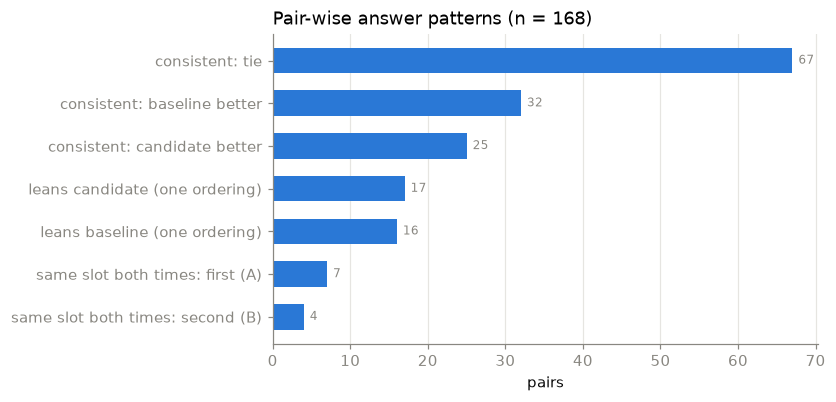

In [7]:
# Figure R2 — pair-wise answer patterns.
fig, ax = plt.subplots(figsize=(6.4, 0.38 * len(patterns) + 1))
figures.bar_counts(ax, patterns.to_dict(), "Pair-wise answer patterns", "pairs")
save(fig, "R2_pairwise_patterns"); plt.show()

## 5. Point-wise scores

The judge's 1–10 score of every execution's first reply (D34), both runs, and
per execution the change against the case's baseline entry.

In [8]:
score_dist = pd.DataFrame({name: f["score"].value_counts() for name, f in runs.items()}).fillna(0).astype(int).sort_index()
by_fn_score = pd.concat({name: f.groupby("function")["score"].agg(["count", "mean", "std", "median"]) for name, f in runs.items()}, axis=1).round(2)
display(score_dist.T)
by_fn_score

score,1,2,4,6,7,8,9,10
baseline,1,1,1,1,11,22,27,112
regression,0,0,0,1,4,27,21,123


baseline                    regression                   
                count  mean   std median      count  mean   std median
function                                                              
advisory           32  9.91  0.30   10.0         32  9.94  0.25   10.0
factual_qa         56  8.50  1.90    9.0         56  8.93  1.09    9.0
scheduling         52  9.58  0.82   10.0         52  9.81  0.53   10.0
venue_lookup       36  9.39  0.87   10.0         36  9.47  0.81   10.0

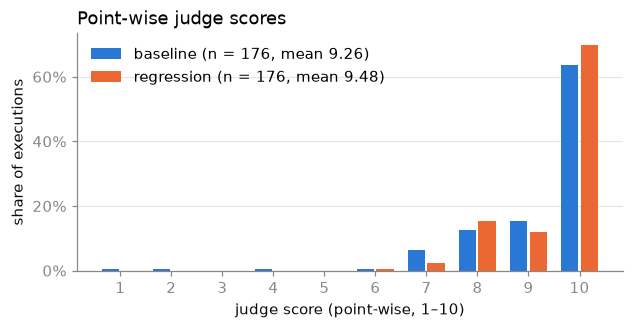

In [9]:
# Figure R3 — score distribution per run (share of executions per score).
fig, ax = plt.subplots(figsize=(6.4, 2.8))
scores = list(range(1, 11))
w = 0.38
for i, (name, f) in enumerate(runs.items()):
    counts = f["score"].value_counts()
    total = counts.sum()
    ax.bar([s + (i - 0.5) * w for s in scores], [counts.get(s, 0) / total for s in scores], width=w - 0.04,
           color=RUN_COLOR[name], label=f"{name} (n = {total}, mean {f['score'].mean():.2f})")
ax.set_xticks(scores); ax.set_xlabel("judge score (point-wise, 1–10)")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax.set_ylabel("share of executions")
ax.grid(axis="y", color=figures.GRID, linewidth=0.8); ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper left")
ax.set_title("Point-wise judge scores")
save(fig, "R3_score_distribution"); plt.show()

In [10]:
base_scores = {s["execution_id"]: s["score"] for s in scores_for(BASELINE_RUN_ID)}
cand_scores = {s["execution_id"]: s["score"] for s in scores_for(CANDIDATE_RUN_ID)}
deltas = pd.DataFrame([{"case": c.case_id, "delta": cand_scores.get(c.execution_id) - base_scores.get(c.baseline_execution_id),
                        "passed": c.passed}
                       for c in comparisons
                       if cand_scores.get(c.execution_id) is not None and base_scores.get(c.baseline_execution_id) is not None])
print(f"score change against the baseline entry, per execution: mean {deltas['delta'].mean():+.2f}, "
      f"median {deltas['delta'].median():+.0f}, n = {len(deltas)}")
print("the baseline entry is each case's best execution (D86), so a negative mean is expected with no change")
deltas["delta"].value_counts().sort_index().rename("executions").to_frame().T

score change against the baseline entry, per execution: mean -0.13, median +0, n = 176
the baseline entry is each case's best execution (D86), so a negative mean is expected with no change


delta,-3,-2,-1,0,1,2
executions,1,9,27,121,11,7


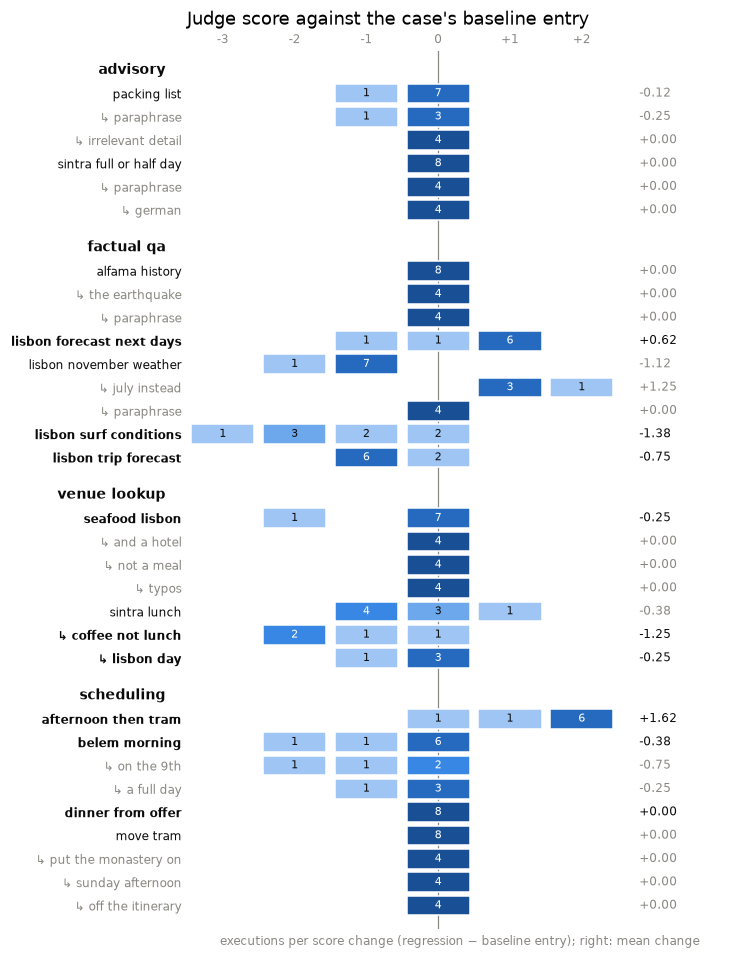

In [11]:
# Figure R4 — score change against the baseline entry, per case, on R1's layout.
# Each cell: how many of the case's executions scored that much above or below its baseline entry.
cols = list(range(int(deltas["delta"].min()), int(deltas["delta"].max()) + 1))
delta_rows, notes = [], []
for r in grid_rows:
    d = deltas[deltas["case"] == r["case"]]["delta"]
    delta_rows.append({**r, "counts": d.value_counts().to_dict()})
    notes.append(f"{d.mean():+.2f}" if len(d) else "–")
fig, ax = plt.subplots(figsize=(6.4, 0.24 * (len(delta_rows) + 2 * len(FUNCTIONS)) + 1.0))
figures.count_grid(ax, delta_rows, cols, "Judge score against the case's baseline entry",
                   "executions per score change (regression − baseline entry); right: mean change",
                   mark_column=0, right=notes)
save(fig, "R4_score_delta_per_case"); plt.show()

## 6. Cost, latency and recovered tool errors

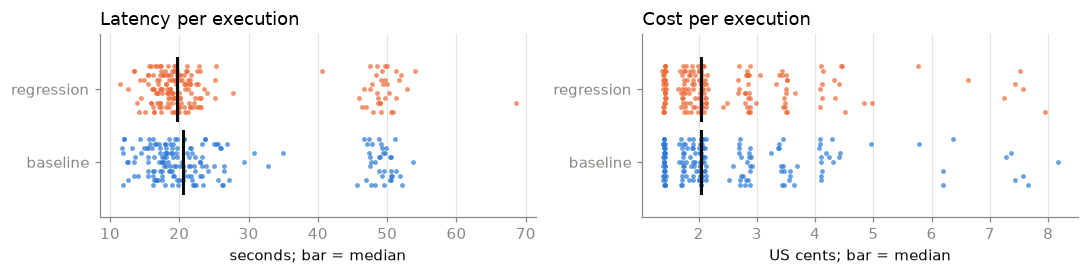

In [12]:
# Figure R5 — latency and cost per execution, both runs, one panel each (different scales).
fig, axs = plt.subplots(1, 2, figsize=(10, 2.6))
for ax, col, scale, title, xlabel in ((axs[0], "latency_ms", 1000, "Latency per execution", "seconds"),
                                      (axs[1], "cost_usd", 0.01, "Cost per execution", "US cents")):
    for i, (name, f) in enumerate(runs.items()):
        vals = list(f[col] / scale)
        jit = [((j * 7) % 11 - 5) * 0.025 + (i - 0.5) * 0.4 for j in range(len(vals))]
        ax.scatter(vals, jit, s=10, color=RUN_COLOR[name], alpha=0.7, linewidth=0, label=name)
        ax.plot([statistics.median(vals)] * 2, [(i - 0.5) * 0.4 - 0.17, (i - 0.5) * 0.4 + 0.17], color=figures.INK, linewidth=2)
    ax.set_yticks([-0.2, 0.2], list(runs)); ax.set_ylim(-0.5, 0.5)
    ax.set_xlabel(xlabel + "; bar = median"); ax.set_title(title)
    ax.grid(axis="x", color=figures.GRID, linewidth=0.8); ax.set_axisbelow(True)
fig.tight_layout(); save(fig, "R5_latency_cost"); plt.show()

In [13]:
run_turns = {name: [t for ex in analysis.simulated_executions(db.admin(), [rid])[0] for t in ex]
             for name, rid in (("baseline", BASELINE_RUN_ID), ("regression", CANDIDATE_RUN_ID))}
rec = {name: analysis.recovered_error_rates(t) for name, t in run_turns.items()}
tbl = pd.concat({name: pd.DataFrame([vars(r) for r in rs]).set_index("group") for name, rs in rec.items()}, axis=1)
errored = tbl.index[(tbl.xs("failures", axis=1, level=1) > 0).any(axis=1)]
print("tool calls that came back an error in a turn that still answered (P2's measure, D103):")
tbl.loc[errored].style.format({c: "{:.1%}" for c in tbl.columns if c[1] == "rate"})

tool calls that came back an error in a turn that still answered (P2's measure, D103):


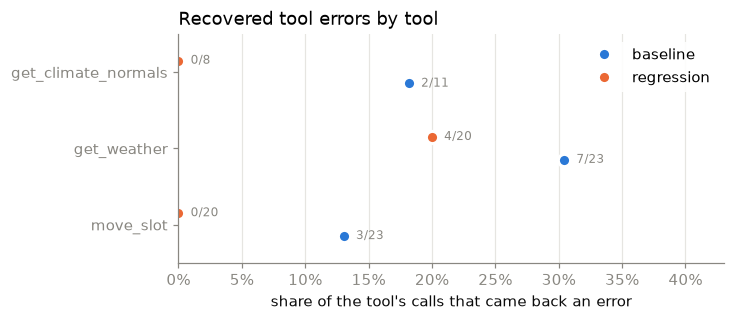

In [14]:
# Figure R6 — recovered tool errors per tool, both runs.
fig, ax = plt.subplots(figsize=(6.4, 0.5 * max(len(errored), 1) + 1.2))
figures.rate_plot(ax, {name: [r for r in rs if r.group in errored] for name, rs in rec.items()},
                  "Recovered tool errors by tool", "share of the tool's calls that came back an error",
                  colors=RUN_COLOR)
save(fig, "R6_recovered_errors"); plt.show()

In [15]:
print(f"figures written to {save.dir.resolve()}")

figures written to C:\Users\gian-\Documents\GitHub\trip_tonic\research\regression-testing\notebooks\sim\figures\regression
